<a href="https://colab.research.google.com/github/CodeDotcom2/CSC173-group-8/blob/main/06_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q -U transformers datasets accelerate scikit-learn pandas==2.2.3 pyarrow==23.0.1 huggingface_hub

In [ ]:
import sys, subprocess, platform
import torch, psutil, transformers, datasets, sklearn, pyarrow
import pandas as pd, numpy as np

print('Python      :', platform.python_version())
for m in [torch, transformers, datasets, sklearn, pd, np, pyarrow]:
    print(f'{m.__name__:<13}:', m.__version__)

print('\nSystem RAM  :', round(psutil.virtual_memory().total / 1e9, 1), 'GB')
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print('GPU         :', p.name, '|', round(p.total_memory / 1e9, 1), 'GB memory')
    try:
        print(subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout)
    except FileNotFoundError:
        print('nvidia-smi not found (GPU still usable by PyTorch).')
else:
    print('\nWARNING: no GPU found. In Colab: Runtime > Change runtime type > select a GPU, then rerun.')
    print('Without a GPU the toy test still works but real training will be far too slow.')

Python      : 3.13.16
torch        : 2.14.1+cu130
transformers : 5.22.2
datasets     : 5.0.1
sklearn      : 1.9.1
pandas       : 2.2.3
numpy        : 2.4.6
pyarrow      : 23.0.1

System RAM  : 13.6 GB
GPU         : Tesla T4 | 15.6 GB memory
Wed Nov 11 14:42:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |               

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive/fever_project'
if not os.path.isdir(ROOT):
    raise FileNotFoundError(
        f'{ROOT} not found.')

SUBDIRS = ['data/evidence', 'data/processed', 'models', 'results', 'checkpoints', 'notebooks']
for d in SUBDIRS:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)          # harmless if they already exist

LABELS   = ['SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO']  # fixed order for everyone
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

CONTRACT_COLS = ['id', 'claim', 'evidence', 'label', 'label_id', 'evidence_source', 'n_sent']

def check_contract(df, name='dataframe'):
    """Fail loudly if a table does not follow the team's data contract."""
    missing = [c for c in CONTRACT_COLS if c not in df.columns]
    assert not missing, f'{name}: missing columns {missing}'
    assert df['id'].is_unique, f'{name}: duplicate ids'
    assert df['label'].isin(LABELS).all(), f'{name}: unexpected label strings'
    assert (df['label'].map(label2id) == df['label_id']).all(), f'{name}: label_id does not match label'
    assert df['claim'].str.len().gt(0).all() and df['evidence'].str.len().gt(0).all(), f'{name}: empty claim or evidence'
    print(f'{name}: contract OK ({len(df)} rows)')

print('ROOT contents:', sorted(os.listdir(ROOT)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT contents: ['checkpoints', 'data', 'models', 'notebooks', 'pipeline_run_full', 'pipeline_run_full_v3', 'pipeline_run_smoke', 'reports', 'results']


In [ ]:
# (evidence, supported claim, refuted claim, not-enough-info claim)
FACTS = [
 ('The Eiffel Tower is a wrought-iron lattice tower in Paris, France.',
  'The Eiffel Tower is located in Paris.', 'The Eiffel Tower is located in London.',
  'The Eiffel Tower was designed by a team of three engineers.'),
 ('Mount Everest is the highest mountain above sea level and is located in the Himalayas.',
  'Mount Everest is in the Himalayas.', 'Mount Everest is in the Andes.',
  'Mount Everest was first climbed by a team of four people.'),
 ('Water boils at 100 degrees Celsius at standard atmospheric pressure.',
  'Water boils at 100 degrees Celsius at standard pressure.', 'Water boils at 50 degrees Celsius at standard pressure.',
  'Salt water boils at 105 degrees Celsius.'),
 ('Albert Einstein was a German-born theoretical physicist who developed the theory of relativity.',
  'Einstein developed the theory of relativity.', 'Einstein was a French chemist.',
  'Einstein played the violin.'),
 ('The Nile is a major river in northeastern Africa that flows into the Mediterranean Sea.',
  'The Nile flows into the Mediterranean Sea.', 'The Nile flows into the Pacific Ocean.',
  'The Nile is the longest river in the world.'),
 ('Tokyo is the capital city of Japan.',
  'Tokyo is the capital of Japan.', 'Tokyo is the capital of China.',
  'Tokyo has hosted the Olympic Games twice.'),
 ('The Amazon rainforest covers much of northwestern Brazil and extends into Colombia, Peru and other South American countries.',
  'The Amazon rainforest extends into Peru.', 'The Amazon rainforest is located in Australia.',
  'The Amazon rainforest contains more than a thousand bird species.'),
 ('Marie Curie was a Polish-born physicist and chemist who conducted pioneering research on radioactivity.',
  'Marie Curie researched radioactivity.', 'Marie Curie was an American painter.',
  'Marie Curie had two daughters.'),
 ('The Great Wall of China is a series of fortifications built across the northern borders of ancient Chinese states.',
  'The Great Wall of China is a series of fortifications.', 'The Great Wall of China is a single modern building in Brazil.',
  'Parts of the Great Wall were built from rammed earth.'),
 ('Python is a high-level programming language first released in 1991.',
  'Python was first released in 1991.', 'Python was first released in 2015.',
  'Python is the most widely used language in finance.'),
 ('The Pacific Ocean is the largest and deepest of the five oceanic divisions of the Earth.',
  'The Pacific Ocean is the largest ocean.', 'The Pacific Ocean is the smallest ocean.',
  'The Pacific Ocean contains more than twenty thousand islands.'),
 ('William Shakespeare was an English playwright who wrote Hamlet and Macbeth.',
  'Shakespeare wrote Hamlet.', 'Shakespeare was a Russian composer.',
  'Shakespeare had three children.'),
 ('The human heart has four chambers: two atria and two ventricles.',
  'The human heart has four chambers.', 'The human heart has two chambers.',
  'The human heart beats about seventy times per minute at rest.'),
 ('Canberra is the capital city of Australia.',
  'Canberra is the capital of Australia.', 'Canberra is the capital of New Zealand.',
  'Canberra was founded in the twentieth century.'),
 ('The Moon orbits the Earth about once every 27 days.',
  'The Moon orbits the Earth.', 'The Moon takes about one year to orbit the Earth.',
  'The Moon is about 384,000 kilometres from the Earth.'),
 ('Leonardo da Vinci was an Italian polymath who painted the Mona Lisa.',
  'Leonardo da Vinci painted the Mona Lisa.', 'Leonardo da Vinci was a Japanese painter.',
  'Leonardo da Vinci designed flying machines.'),
 ('Jupiter is the largest planet in the Solar System.',
  'No planet in the Solar System is larger than Jupiter.', 'Mercury is the largest planet in the Solar System.',
  'Jupiter has more than fifty moons.'),
 ('The Berlin Wall separated East Berlin from West Berlin from 1961 until 1989.',
  'The Berlin Wall divided East and West Berlin.', 'The Berlin Wall stood until 1975.',
  'The Berlin Wall was about 155 kilometres long.'),
 ('Honey bees are social insects that live in colonies and produce honey.',
  'Honey bees live in colonies.', 'Honey bees are solitary animals that never form groups.',
  'Honey bees can recognize human faces.'),
 ('The Sahara is the largest hot desert in the world and is located in northern Africa.',
  'The Sahara is in Africa.', 'The Sahara is located in South America.',
  'The Sahara receives snow every winter.'),
]
assert len(FACTS) == 20 and all(len(f) == 4 for f in FACTS), 'FACTS must be 20 tuples of 4 strings'

rows = []
for i, (ev, sup, ref, nei) in enumerate(FACTS):
    for k, (claim, label) in enumerate([(sup, 'SUPPORTS'), (ref, 'REFUTES'), (nei, 'NOT ENOUGH INFO')]):
        rows.append({'id': i * 3 + k, 'claim': claim, 'evidence': ev, 'label': label})

toy = pd.DataFrame(rows)
toy['label_id'] = toy['label'].map(label2id).astype(int)
toy['evidence_source'] = 'toy'
toy['n_sent'] = 1
toy = toy[CONTRACT_COLS].reset_index(drop=True)

check_contract(toy, 'toy_pairs')
assert len(toy) == 60, f'expected 60 rows, got {len(toy)}'
assert (toy['label'].value_counts() == 20).all(), 'each label must have exactly 20 rows'
print(toy['label'].value_counts())
print(toy.dtypes)
print(toy.sample(6, random_state=0)[['claim', 'evidence', 'label']].to_string(max_colwidth=70))

toy_pairs: contract OK (60 rows)
label
SUPPORTS           20
REFUTES            20
NOT ENOUGH INFO    20
Name: count, dtype: int64
id                  int64
claim              object
evidence           object
label              object
label_id            int64
evidence_source    object
n_sent              int64
dtype: object
                                                          claim                                                               evidence            label
26        Parts of the Great Wall were built from rammed earth.  The Great Wall of China is a series of fortifications built across...  NOT ENOUGH INFO
35                              Shakespeare had three children.  William Shakespeare was an English playwright who wrote Hamlet and...  NOT ENOUGH INFO
59                       The Sahara receives snow every winter.  The Sahara is the largest hot desert in the world and is located i...  NOT ENOUGH INFO
28                           Python was first released in 2015.  

In [ ]:
toy_path = f'{ROOT}/data/processed/toy_pairs.parquet'
toy.to_parquet(toy_path, index=False)

back = pd.read_parquet(toy_path)
pd.testing.assert_frame_equal(toy, back, check_dtype=True)     # raises if anything differs
check_contract(back, 'toy_pairs (reloaded)')

print('Saved:', toy_path)
print('File size (KB):', round(os.path.getsize(toy_path) / 1024, 1))
print('Files in data/processed:', sorted(os.listdir(f'{ROOT}/data/processed')))

toy_pairs (reloaded): contract OK (60 rows)
Saved: /content/drive/MyDrive/fever_project/data/processed/toy_pairs.parquet
File size (KB): 8.1
Files in data/processed: ['_toy_val_pairs.parquet', 'claims_train_flat.parquet', 'claims_val_flat.parquet', 'gold_train.parquet', 'gold_val.parquet', 'nei_train.parquet', 'nei_train_mini.parquet', 'nei_val.parquet', 'nei_val_mini.parquet', 'toy_pairs.parquet', 'train_pairs.parquet', 'train_pairs_mini.parquet', 'train_tok', 'train_tok_mini', 'val_pairs.parquet', 'val_pairs_mini.parquet', 'val_tok', 'val_tok_mini']


In [ ]:
import os, dataclasses, torch, numpy as np, pandas as pd, transformers
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding)
from transformers.trainer_utils import get_last_checkpoint
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

MODEL_NAME   = 'distilbert-base-uncased'
MAX_LEN      = 128
WARMUP_RATIO = 0.06
TF_MAJOR     = int(transformers.__version__.split('.')[0])
print('transformers', transformers.__version__, '| major', TF_MAJOR)

# ---- tokenizer (needs internet; fails with a clear message) ----
try:
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
except Exception as e:
    raise RuntimeError(f'Could not load tokenizer {MODEL_NAME}. Check the internet connection and retry. Original error: {e}')

# ---- tokenization used for the toy test (Member 2 uses the same settings for the real data) ----
def tokenize_pairs(df):
    ds = Dataset.from_pandas(df[['claim', 'evidence', 'label_id']].rename(columns={'label_id': 'labels'}),
                             preserve_index=False)
    return ds.map(lambda b: tok(b['claim'], b['evidence'], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=['claim', 'evidence'])

# ---- model factory: always returns a FRESH model (new, untrained 3-way head) ----
def new_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3, id2label=id2label, label2id=label2id)

# ---- metrics ----
def compute_metrics(p):
    logits = p.predictions[0] if isinstance(p.predictions, (tuple, list)) else p.predictions
    preds = np.argmax(logits, axis=-1)
    pr, rc, f1, _ = precision_recall_fscore_support(p.label_ids, preds, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(p.label_ids, preds),
            'macro_precision': pr, 'macro_recall': rc, 'macro_f1': f1}

# ---- training arguments (roadmap values; warmup name depends on the transformers version) ----
VALID_ARGS = {f.name for f in dataclasses.fields(TrainingArguments)}

def make_args(output_dir, **overrides):
    cfg = dict(output_dir=output_dir, learning_rate=3e-5, num_train_epochs=3,
               per_device_train_batch_size=32, per_device_eval_batch_size=64,
               weight_decay=0.01, fp16=torch.cuda.is_available(),
               eval_strategy='steps', eval_steps=1000, save_strategy='steps', save_steps=1000,
               logging_steps=100, save_total_limit=2,
               load_best_model_at_end=True, metric_for_best_model='macro_f1', greater_is_better=True,
               report_to='none', seed=42)
    if TF_MAJOR >= 5:
        cfg['warmup_steps'] = WARMUP_RATIO      # v5: a float below 1 means a ratio of total steps
    else:
        cfg['warmup_ratio'] = WARMUP_RATIO
    cfg.update(overrides)
    unknown = sorted(k for k in cfg if k not in VALID_ARGS)
    if unknown:
        raise ValueError(f'These TrainingArguments names are not valid in transformers {transformers.__version__}: {unknown}. '
                         'Copy this message to the group chat and check the current Hugging Face docs.')
    return TrainingArguments(**cfg)

def make_trainer(model, args, train_ds, val_ds):
    return Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                   data_collator=DataCollatorWithPadding(tok, pad_to_multiple_of=8),
                   compute_metrics=compute_metrics, processing_class=tok)

# ---- resume logic ----
def find_last_checkpoint(output_dir):
    return get_last_checkpoint(output_dir) if os.path.isdir(output_dir) else None

def run_training(trainer, output_dir):
    last = find_last_checkpoint(output_dir)
    print('Resuming from checkpoint:' if last else 'No checkpoint found; starting fresh.', last or '')
    return trainer.train(resume_from_checkpoint=last)

print('Helpers defined.')

transformers 5.22.2 | major 5


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Helpers defined.


In [ ]:
toy = pd.read_parquet(f'{ROOT}/data/processed/toy_pairs.parquet')
check_contract(toy, 'toy_pairs')

fact_idx = toy['id'] // 3                                   # 3 claims per fact, facts 0..19
toy_train = toy[fact_idx < 15].reset_index(drop=True)
toy_val   = toy[fact_idx >= 15].reset_index(drop=True)
assert set(toy_train['evidence']).isdisjoint(set(toy_val['evidence'])), 'evidence leaked across splits'
print('toy_train:', len(toy_train), '| toy_val:', len(toy_val))
print(toy_train['label'].value_counts().to_dict(), toy_val['label'].value_counts().to_dict())

toy_train_ds = tokenize_pairs(toy_train)
toy_val_ds   = tokenize_pairs(toy_val)
assert (np.array(toy_val_ds['labels']) == toy_val['label_id'].values).all(), 'validation order mismatch'
print(toy_train_ds)

ex = tok.convert_ids_to_tokens(toy_train_ds[0]['input_ids'])
print(ex[:3], '...', ex[-3:])

toy_pairs: contract OK (60 rows)
toy_train: 45 | toy_val: 15
{'SUPPORTS': 15, 'REFUTES': 15, 'NOT ENOUGH INFO': 15} {'SUPPORTS': 5, 'REFUTES': 5, 'NOT ENOUGH INFO': 5}


Map:   0%|          | 0/45 [00:00<?, ? examples/s]

Map:   0%|          | 0/15 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 45
})
['[CLS]', 'the', 'e'] ... ['france', '.', '[SEP]']


In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = new_model().to(device)

# 1) Arguments build correctly and the warmup setting is what we intended
args = make_args(f'{ROOT}/checkpoints/_toy_check')
print('fp16:', args.fp16, '| lr:', args.learning_rate, '| epochs:', args.num_train_epochs,
      '| warmup_steps:', args.warmup_steps, '| warmup_ratio:', getattr(args, 'warmup_ratio', 'n/a'))

# 2) One forward pass on a padded batch
batch = DataCollatorWithPadding(tok, pad_to_multiple_of=8)([toy_train_ds[i] for i in range(4)])
batch = {k: v.to(device) for k, v in batch.items()}
with torch.no_grad():
    out = model(**batch)
print('logits shape:', tuple(out.logits.shape), '| loss:', round(out.loss.item(), 4))
assert tuple(out.logits.shape) == (4, 3) and torch.isfinite(out.loss)

# 3) Metrics function on fake predictions
class _P:                                                    # mimics the Trainer's EvalPrediction
    predictions = np.array([[2., 0., 0.], [0., 2., 0.], [0., 0., 2.], [2., 0., 0.]])
    label_ids = np.array([0, 1, 2, 1])
print(compute_metrics(_P))

# 4) Trainer builds, and resume logic works on an empty folder
trainer = make_trainer(model, args, toy_train_ds, toy_val_ds)
print('Trainer ready. Last checkpoint in a fresh folder:', find_last_checkpoint(args.output_dir))

if device == 'cuda':
    print('GPU memory allocated (MB):', round(torch.cuda.memory_allocated() / 1e6))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


fp16: True | lr: 3e-05 | epochs: 3 | warmup_steps: 0.06 | warmup_ratio: n/a
logits shape: (4, 3) | loss: 1.0629
{'accuracy': 0.75, 'macro_precision': 0.8333333333333334, 'macro_recall': 0.8333333333333334, 'macro_f1': 0.7777777777777777}
Trainer ready. Last checkpoint in a fresh folder: None
GPU memory allocated (MB): 277


In [ ]:
import gc, shutil, time
from transformers import TrainerCallback

class SimulatedDisconnect(Exception):
    pass

class StopAtStep(TrainerCallback):
    """Raises an error at a chosen step, like a Colab disconnect would stop a run."""
    def __init__(self, step):
        self.step = step
    def on_step_end(self, args, state, control, **kwargs):
        if state.global_step >= self.step:
            raise SimulatedDisconnect(f'simulated disconnect at step {state.global_step}')

SMOKE_DIR = '/content/smoke_toy'                  # local disk: fast, and nothing here needs to survive
shutil.rmtree(SMOKE_DIR, ignore_errors=True)      # start clean so we do not resume an old run by accident

smoke_over = dict(num_train_epochs=3, per_device_train_batch_size=8, per_device_eval_batch_size=16,
                  eval_steps=6, save_steps=6, logging_steps=2, save_total_limit=2)
# 45 examples / batch 8 = 6 steps per epoch, 3 epochs = 18 steps; evaluate and save every 6 steps

# ---------- Run A: interrupted at step 9 ----------
args_a = make_args(SMOKE_DIR, **smoke_over)
trainer_a = make_trainer(new_model(), args_a, toy_train_ds, toy_val_ds)
trainer_a.add_callback(StopAtStep(9))
t0 = time.time()
try:
    run_training(trainer_a, SMOKE_DIR)
    raise AssertionError('Run A should have been interrupted but finished.')
except SimulatedDisconnect as e:
    print('Run A stopped as planned ->', e)
print('Run A seconds:', round(time.time() - t0, 1))

print('Folder contents after interruption:', sorted(os.listdir(SMOKE_DIR)))
last = find_last_checkpoint(SMOKE_DIR)
print('Last checkpoint found:', last)
assert last is not None, 'No checkpoint was saved before the interruption.'

# free GPU memory, as a fresh session would have
del trainer_a
gc.collect(); torch.cuda.empty_cache()

# ---------- Run B: new objects, same settings, resumes from the checkpoint ----------
args_b = make_args(SMOKE_DIR, **smoke_over)
trainer_b = make_trainer(new_model(), args_b, toy_train_ds, toy_val_ds)
t0 = time.time()
result_b = run_training(trainer_b, SMOKE_DIR)
print('Run B seconds:', round(time.time() - t0, 1))
print('Final global step:', trainer_b.state.global_step)
assert trainer_b.state.global_step == 18, 'Run B did not reach step 18'

print('train metrics:', result_b.metrics)
log = pd.DataFrame(trainer_b.state.log_history)
cols = [c for c in ['step', 'epoch', 'loss', 'eval_loss', 'eval_accuracy', 'eval_macro_f1'] if c in log.columns]
print(log[cols].to_string())

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


No checkpoint found; starting fresh. 


Step,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
6,1.102026,1.097656,0.400000,0.267857,0.400000,0.320513


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Run A stopped as planned -> simulated disconnect at step 9
Run A seconds: 14.0
Folder contents after interruption: ['checkpoint-6']
Last checkpoint found: /content/smoke_toy/checkpoint-6


... (3 outputs left out)

Step,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
12,1.094885,1.095052,0.466667,0.318182,0.466667,0.356481
18,1.086902,1.094141,0.533333,0.555556,0.533333,0.484127


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Run B seconds: 10.9
Final global step: 18
train metrics: {'train_runtime': 9.7098, 'train_samples_per_second': 9.269, 'train_steps_per_second': 1.236, 'total_flos': 1293650010000.0, 'train_loss': 1.0946339964866638, 'epoch': 3.0}
    step     epoch      loss  eval_loss  eval_accuracy  eval_macro_f1
0      2  0.333333  1.127960        NaN            NaN            NaN
1      4  0.666667  1.111145        NaN            NaN            NaN
2      6  1.000000  1.102026        NaN            NaN            NaN
3      6  1.000000       NaN   1.097656       0.400000       0.320513
4      8  1.333333  1.087830        NaN            NaN            NaN
5     10  1.666667  1.118225        NaN            NaN            NaN
6     12  2.000000  1.094885        NaN            NaN            NaN
7     12  2.000000       NaN   1.095052       0.466667       0.356481
8     14  2.333333  1.080963        NaN            NaN            NaN
9     16  2.666667  1.098999        NaN            NaN            NaN


In [ ]:
pred_out = trainer_b.predict(toy_val_ds, metric_key_prefix='val')
print('prediction array shape:', pred_out.predictions.shape)      # (15, 3)
print({k: round(float(v), 4) for k, v in pred_out.metrics.items()})
assert pred_out.predictions.shape == (15, 3)
assert (pred_out.label_ids == toy_val['label_id'].values).all()
print('Predicted labels:', [id2label[i] for i in pred_out.predictions.argmax(-1)])

prediction array shape: (15, 3)
{'val_loss': 1.0941, 'val_accuracy': 0.5333, 'val_macro_precision': 0.5556, 'val_macro_recall': 0.5333, 'val_macro_f1': 0.4841, 'val_runtime': 0.0202, 'val_samples_per_second': 741.253, 'val_steps_per_second': 49.417}
Predicted labels: ['NOT ENOUGH INFO', 'SUPPORTS', 'NOT ENOUGH INFO', 'SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO', 'NOT ENOUGH INFO', 'NOT ENOUGH INFO', 'NOT ENOUGH INFO', 'REFUTES', 'REFUTES', 'NOT ENOUGH INFO', 'NOT ENOUGH INFO', 'NOT ENOUGH INFO', 'NOT ENOUGH INFO']


In [ ]:
DRIVE_TEST = f'{ROOT}/checkpoints/_toy_drive_test'
shutil.rmtree(DRIVE_TEST, ignore_errors=True)

args_d = make_args(DRIVE_TEST, max_steps=2, per_device_train_batch_size=8,
                   eval_strategy='no', load_best_model_at_end=False,
                   save_strategy='steps', save_steps=2, logging_steps=1, save_total_limit=1)
trainer_d = make_trainer(new_model(), args_d, toy_train_ds, toy_val_ds)
t0 = time.time()
trainer_d.train()
print('Train + checkpoint write seconds:', round(time.time() - t0, 1))

ck = find_last_checkpoint(DRIVE_TEST)
size_mb = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(ck) for f in fs) / 1e6
print('Checkpoint on Drive:', ck, '| size (MB):', round(size_mb))
print('Files:', sorted(os.listdir(ck)))

shutil.rmtree(DRIVE_TEST, ignore_errors=True)     # remove the test folder
shutil.rmtree(f'{ROOT}/checkpoints/_toy_check', ignore_errors=True)   # empty folder from Task 2
print('checkpoints folder now:', sorted(os.listdir(f'{ROOT}/checkpoints')))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
1,1.108398
2,1.129761


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Train + checkpoint write seconds: 4.4
Checkpoint on Drive: /content/drive/MyDrive/fever_project/checkpoints/_toy_drive_test/checkpoint-2 | size (MB): 804
Files: ['config.json', 'model.safetensors', 'optimizer.pt', 'rng_state.pth', 'scaler.pt', 'scheduler.pt', 'tokenizer.json', 'tokenizer_config.json', 'trainer_state.json', 'training_args.bin']
checkpoints folder now: ['run1']


In [ ]:
toy_model_dir = f'{ROOT}/models/_toy_model'
trainer_b.save_model(toy_model_dir)
tok.save_pretrained(toy_model_dir)
toy_val.to_parquet(f'{ROOT}/data/processed/_toy_val_pairs.parquet', index=False)
print('Saved:', sorted(os.listdir(toy_model_dir)))

# file names with _toy are temporary test files

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved: ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


In [ ]:
import hashlib
from datasets import load_from_disk

proc = f'{ROOT}/data/processed'
train_pairs = pd.read_parquet(f'{proc}/train_pairs.parquet'); check_contract(train_pairs, 'train_pairs')
val_pairs   = pd.read_parquet(f'{proc}/val_pairs.parquet');   check_contract(val_pairs, 'val_pairs')
train_tok = load_from_disk(f'{proc}/train_tok'); val_tok = load_from_disk(f'{proc}/val_tok')
print('rows:', len(train_tok), len(val_tok), '| expected:', len(train_pairs), len(val_pairs))
assert len(train_tok) == len(train_pairs) and len(val_tok) == len(val_pairs)
assert (np.array(train_tok['labels']) == train_pairs.label_id.values).all()
assert (np.array(val_tok['labels'])   == val_pairs.label_id.values).all()

# re-tokenize 1,000 random rows with OUR tokenizer; they must equal Member 2's stored ids exactly
rng = np.random.default_rng(0)
idx = rng.choice(len(train_pairs), 1000, replace=False)
enc = tok(list(train_pairs.claim.iloc[idx]), list(train_pairs.evidence.iloc[idx]), truncation=True, max_length=MAX_LEN)
same = sum(enc['input_ids'][j] == train_tok[int(i)]['input_ids'] for j, i in enumerate(idx))
print('identical tokenization on 1,000 sampled rows:', same, '/ 1000')
print(tok.decode(train_tok[0]['input_ids'])[:300])

# 13c: file fingerprints (compare with the md5 values in the chat)
for f in ['train_pairs.parquet', 'val_pairs.parquet']:
    print(f, hashlib.md5(open(f'{proc}/{f}', 'rb').read()).hexdigest(), os.path.getsize(f'{proc}/{f}'), 'bytes')

train_pairs: contract OK (145448 rows)
val_pairs: contract OK (9997 rows)
rows: 145448 9997 | expected: 145448 9997
identical tokenization on 1,000 sampled rows: 1000 / 1000
[CLS] michael jackson wrote a song. [SEP] michael joseph jackson ( august 29, 1958 - - june 25, 2009 ) was an american singer, songwriter, record producer, dancer, actor, and philanthropist. his music videos, including those of ` ` beat it ' ', ` ` billie jean ' ', and ` ` thriller ' ' from his 1982
train_pairs.parquet 50ecb2b8171ca23b336865dc4f04f159 32639810 bytes
val_pairs.parquet 9c848e23d5ddb1cf304452e12aef1ba2 1168804 bytes


In [ ]:
from sklearn.model_selection import train_test_split
import time, gc, shutil

def stratified_subset(ds, labels, n, seed=0):
    idx, _ = train_test_split(np.arange(len(labels)), train_size=n, stratify=labels, random_state=seed)
    return ds.select(sorted(idx.tolist()))

sub_train = stratified_subset(train_tok, train_pairs.label_id.values, 10000)
sub_val   = stratified_subset(val_tok,   val_pairs.label_id.values,   2000)
print('subset sizes:', len(sub_train), len(sub_val), '| train label counts:', np.bincount(sub_train['labels']))

SMOKE2 = '/content/smoke_real'
shutil.rmtree(SMOKE2, ignore_errors=True)
steps_per_epoch = len(sub_train) // 32
args_r = make_args(SMOKE2, num_train_epochs=1, eval_steps=100, save_steps=100, logging_steps=25,
                   save_total_limit=1)
trainer_r = make_trainer(new_model(), args_r, sub_train, sub_val)

torch.cuda.reset_peak_memory_stats()
t0 = time.time()
res_r = trainer_r.train()
secs = time.time() - t0
peak = torch.cuda.max_memory_allocated() / 1e9

print(f'\ntraining seconds: {secs:.0f} | examples/second: {len(sub_train) / secs:.1f} | peak GPU memory: {peak:.2f} GB')
full_examples = len(train_tok) * 2
print(f'Rough full-run estimate (2 epochs, training only, from THIS measurement): {full_examples / (len(sub_train) / secs) / 60:.0f} minutes')
log = pd.DataFrame(trainer_r.state.log_history)
print(log[[c for c in ['step', 'loss', 'eval_loss', 'eval_accuracy', 'eval_macro_f1'] if c in log.columns]].to_string())

del trainer_r; gc.collect(); torch.cuda.empty_cache()

subset sizes: 10000 2000 | train label counts: [5503 2047 2450]


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
100,0.859774,1.031784,0.523000,0.651198,0.522841,0.480776
200,0.633363,0.827063,0.657500,0.695667,0.657453,0.642289
300,0.589423,0.705208,0.713000,0.722592,0.712951,0.706036
313,0.589423,0.709932,0.711500,0.721328,0.711446,0.704146


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


training seconds: 52 | examples/second: 190.7 | peak GPU memory: 3.68 GB
Rough full-run estimate (2 epochs, training only, from THIS measurement): 25 minutes
    step      loss  eval_loss  eval_accuracy  eval_macro_f1
0     25  1.042039        NaN            NaN            NaN
1     50  0.995334        NaN            NaN            NaN
2     75  0.939981        NaN            NaN            NaN
3    100  0.859774        NaN            NaN            NaN
4    100       NaN   1.031784         0.5230       0.480776
5    125  0.763386        NaN            NaN            NaN
6    150  0.741498        NaN            NaN            NaN
7    175  0.636634        NaN            NaN            NaN
8    200  0.633363        NaN            NaN            NaN
9    200       NaN   0.827063         0.6575       0.642289
10   225  0.643157        NaN            NaN            NaN
11   250  0.651421        NaN            NaN            NaN
12   275  0.598760        NaN            NaN            NaN
1

In [ ]:
import json, math, time, datetime, shutil, gc
from datasets import load_from_disk

proc      = f'{ROOT}/data/processed'
RUN_NAME  = 'run1'
CKPT_DIR  = f'{ROOT}/checkpoints/{RUN_NAME}'
FINAL_DIR = f'{ROOT}/models/distilbert-fever-v2'           #distilbert-fever-v1 == 2 epoch     distilbert-fever-v2 == 3 epoch
SEG_PATH  = f'{ROOT}/results/{RUN_NAME}_segments.json'

assert torch.cuda.is_available(), 'No GPU. Runtime > Change runtime type > GPU, then rerun Cells 3 and 6.'

train_pairs = pd.read_parquet(f'{proc}/train_pairs.parquet'); check_contract(train_pairs, 'train_pairs')
val_pairs   = pd.read_parquet(f'{proc}/val_pairs.parquet');   check_contract(val_pairs, 'val_pairs')
train_tok   = load_from_disk(f'{proc}/train_tok');            val_tok = load_from_disk(f'{proc}/val_tok')

assert len(train_tok) == len(train_pairs) and len(val_tok) == len(val_pairs), 'row count mismatch'
assert (np.array(train_tok['labels']) == train_pairs.label_id.values).all(), 'train label order mismatch'
assert (np.array(val_tok['labels'])   == val_pairs.label_id.values).all(),   'val label order mismatch'
assert max(len(x) for x in val_tok['input_ids']) <= MAX_LEN and max(len(x) for x in train_tok['input_ids']) <= MAX_LEN

print('train claims:', len(train_tok), '| validation claims:', len(val_tok))
print('train label counts :', np.bincount(train_tok['labels']).tolist(), '(SUPPORTS, REFUTES, NEI)')
print('val label counts   :', np.bincount(val_tok['labels']).tolist())
print('GPU:', torch.cuda.get_device_name(0))

try:
    du = shutil.disk_usage(ROOT)
    print('Drive free space (GB):', round(du.free / 1e9, 1), '(this may reflect the Drive quota; check drive.google.com if unsure)')
except Exception as e:
    print('Could not read Drive free space:', e)

last = find_last_checkpoint(CKPT_DIR)
print('\nExisting checkpoint in', CKPT_DIR, ':', last)
print('Final model folder exists already:', os.path.exists(FINAL_DIR))

train_pairs: contract OK (145448 rows)
val_pairs: contract OK (9997 rows)
train claims: 145448 | validation claims: 9997
train label counts : [80035, 29775, 35638] (SUPPORTS, REFUTES, NEI)
val label counts   : [3333, 3333, 3331]
GPU: Tesla T4
Drive free space (GB): 111.4 (this may reflect the Drive quota; check drive.google.com if unsure)

Existing checkpoint in /content/drive/MyDrive/fever_project/checkpoints/run1 : /content/drive/MyDrive/fever_project/checkpoints/run1/checkpoint-13638
Final model folder exists already: False


In [ ]:
model = new_model()
args  = make_args(CKPT_DIR)        # roadmap values: lr 3e-5, 2 epochs, batch 32/64, wd 0.01, warmup 0.06, fp16, eval/save every 1000 steps
trainer = make_trainer(model, args, train_tok, val_tok)

steps_per_epoch = math.ceil(len(train_tok) / args.per_device_train_batch_size)
total_steps     = steps_per_epoch * int(args.num_train_epochs)
print('steps per epoch:', steps_per_epoch, '| total steps:', total_steps,
      '| evaluations (every', args.eval_steps, 'steps):', total_steps // args.eval_steps)

planned = dict(base_model=MODEL_NAME, labels=LABELS, learning_rate=args.learning_rate, epochs=int(args.num_train_epochs),
               train_batch=args.per_device_train_batch_size, eval_batch=args.per_device_eval_batch_size,
               max_length=MAX_LEN, weight_decay=args.weight_decay, warmup=WARMUP_RATIO, fp16=bool(args.fp16),
               seed=args.seed, eval_steps=args.eval_steps, save_steps=args.save_steps,
               metric_for_best_model=args.metric_for_best_model,
               n_train=len(train_tok), n_val=len(val_tok))
json.dump(planned, open(f'{ROOT}/results/{RUN_NAME}_config_planned.json', 'w'), indent=2)
print(json.dumps(planned, indent=2))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


steps per epoch: 4546 | total steps: 13638 | evaluations (every 1000 steps): 13
{
  "base_model": "distilbert-base-uncased",
  "labels": [
    "SUPPORTS",
    "REFUTES",
    "NOT ENOUGH INFO"
  ],
  "learning_rate": 3e-05,
  "epochs": 3,
  "train_batch": 32,
  "eval_batch": 64,
  "max_length": 128,
  "weight_decay": 0.01,
  "warmup": 0.06,
  "fp16": true,
  "seed": 42,
  "eval_steps": 1000,
  "save_steps": 1000,
  "metric_for_best_model": "macro_f1",
  "n_train": 145448,
  "n_val": 9997
}


In [ ]:
def load_segments():
    return json.load(open(SEG_PATH)) if os.path.exists(SEG_PATH) else []

def save_segments(segs):
    json.dump(segs, open(SEG_PATH, 'w'), indent=2)

#last = find_last_checkpoint(CKPT_DIR)
last = None
segs = load_segments()
seg = {'started_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(),
       'resumed_from': last, 'gpu': torch.cuda.get_device_name(0), 'status': 'running', 'seconds': None}
segs.append(seg); save_segments(segs)          # if Colab dies, this stays as 'running' (unfinished)

t0 = time.time()
try:
    result = trainer.train(resume_from_checkpoint=last)
    seg.update(status='finished', seconds=round(time.time() - t0, 1))
except BaseException as e:
    seg.update(status=f'interrupted: {type(e).__name__}', seconds=round(time.time() - t0, 1))
    save_segments(segs)
    print('\nTraining stopped:', type(e).__name__, '. Rerun Cells 15, 16 and 17 to resume from the last checkpoint.')
    raise
save_segments(segs)

print('\nThis segment took (minutes):', round(seg['seconds'] / 60, 1))
print('train metrics:', result.metrics)
print('best checkpoint:', trainer.state.best_model_checkpoint, '| best macro_f1:', trainer.state.best_metric)

Step,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1000,0.473472,0.588966,0.772332,0.775172,0.772312,0.769417
2000,0.365782,0.555225,0.787836,0.801290,0.787831,0.784937
3000,0.348907,0.538100,0.809543,0.815406,0.809527,0.807252
4000,0.320411,0.482695,0.826948,0.827623,0.826934,0.825617
5000,0.246524,0.531160,0.821847,0.826199,0.821823,0.819273
6000,0.260632,0.504461,0.826548,0.826859,0.826530,0.825108
7000,0.243249,0.489687,0.836851,0.837291,0.836833,0.835273
8000,0.229263,0.517850,0.832550,0.834848,0.832536,0.831199
9000,0.230608,0.507766,0.830049,0.832732,0.830040,0.829123
10000,0.167744,0.549715,0.833250,0.833791,0.833236,0.832177


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


This segment took (minutes): 25.4
train metrics: {'train_runtime': 1525.9293, 'train_samples_per_second': 285.953, 'train_steps_per_second': 8.938, 'total_flos': 1.4414183725502592e+16, 'train_loss': 0.2732315147040194, 'epoch': 3.0}
best checkpoint: /content/drive/MyDrive/fever_project/checkpoints/run1/checkpoint-12000 | best macro_f1: 0.8369782989027851


In [ ]:
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding

assert not os.path.exists(FINAL_DIR), f'{FINAL_DIR} already exists. Rename or move it first so a finished model is not overwritten.'
trainer.save_model(FINAL_DIR)
tok.save_pretrained(FINAL_DIR)

log = pd.DataFrame(trainer.state.log_history)
log.to_csv(f'{ROOT}/results/training_log.csv', index=False)

segs = load_segments()
done = [s for s in segs if s['status'] == 'finished']
unfinished = [s for s in segs if s['status'] != 'finished']
total_min = round(sum(s['seconds'] for s in done) / 60, 1)

config = dict(planned,
              gpu=torch.cuda.get_device_name(0),
              versions=dict(torch=torch.__version__, transformers=transformers.__version__),
              training_minutes_recorded=total_min, segments=len(segs), unfinished_segments=len(unfinished),
              best_checkpoint=trainer.state.best_model_checkpoint, best_val_macro_f1_during_training=trainer.state.best_metric,
              final_global_step=trainer.state.global_step,
              data_notes='fill in: wiki coverage, dropped claims, NEI method, NEI audit result')
json.dump(config, open(f'{ROOT}/results/training_config.json', 'w'), indent=2)
print(json.dumps(config, indent=2))

# reload check: the saved model must produce the same logits as the in-memory model
reloaded = AutoModelForSequenceClassification.from_pretrained(FINAL_DIR).to('cuda').eval()
batch = DataCollatorWithPadding(tok)([val_tok[i] for i in range(16)])
batch.pop('labels'); batch.pop('token_type_ids', None)
batch = {k: v.to('cuda') for k, v in batch.items()}
with torch.no_grad():
    a = trainer.model.eval()(**batch).logits.float().cpu()
    b = reloaded(**batch).logits.float().cpu()
print('reloaded model matches in-memory model:', bool(torch.allclose(a, b, atol=1e-3)))
print('saved files:', sorted(os.listdir(FINAL_DIR)))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{
  "base_model": "distilbert-base-uncased",
  "labels": [
    "SUPPORTS",
    "REFUTES",
    "NOT ENOUGH INFO"
  ],
  "learning_rate": 3e-05,
  "epochs": 3,
  "train_batch": 32,
  "eval_batch": 64,
  "max_length": 128,
  "weight_decay": 0.01,
  "warmup": 0.06,
  "fp16": true,
  "seed": 42,
  "eval_steps": 1000,
  "save_steps": 1000,
  "metric_for_best_model": "macro_f1",
  "n_train": 145448,
  "n_val": 9997,
  "gpu": "Tesla T4",
  "versions": {
    "torch": "2.14.1+cu130",
    "transformers": "5.22.2"
  },
  "training_minutes_recorded": 42.7,
  "segments": 4,
  "unfinished_segments": 2,
  "best_checkpoint": "/content/drive/MyDrive/fever_project/checkpoints/run1/checkpoint-12000",
  "best_val_macro_f1_during_training": 0.8369782989027851,
  "final_global_step": 13638,
  "data_notes": "fill in: wiki coverage, dropped claims, NEI method, NEI audit result"
}


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

reloaded model matches in-memory model: False
saved files: ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


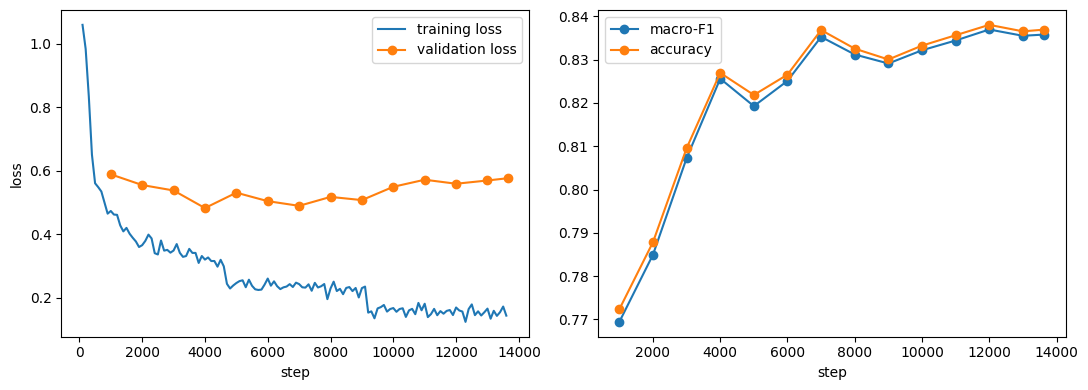

 step  eval_loss  eval_accuracy  eval_macro_f1
 1000   0.588966       0.772332       0.769417
 2000   0.555225       0.787836       0.784937
 3000   0.538100       0.809543       0.807252
 4000   0.482695       0.826948       0.825617
 5000   0.531160       0.821847       0.819273
 6000   0.504461       0.826548       0.825108
 7000   0.489687       0.836851       0.835273
 8000   0.517850       0.832550       0.831199
 9000   0.507766       0.830049       0.829123
10000   0.549715       0.833250       0.832177
11000   0.571960       0.835651       0.834435
12000   0.559317       0.838051       0.836978
13000   0.569561       0.836551       0.835523
13638   0.576602       0.836951       0.835810


In [ ]:
import matplotlib.pyplot as plt
tr = log.dropna(subset=['loss']);      ev = log.dropna(subset=['eval_loss'])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(tr['step'], tr['loss'], label='training loss'); ax[0].plot(ev['step'], ev['eval_loss'], marker='o', label='validation loss')
ax[0].set_xlabel('step'); ax[0].set_ylabel('loss'); ax[0].legend()
ax[1].plot(ev['step'], ev['eval_macro_f1'], marker='o', label='macro-F1'); ax[1].plot(ev['step'], ev['eval_accuracy'], marker='o', label='accuracy')
ax[1].set_xlabel('step'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{ROOT}/results/training_curves.png', dpi=150); plt.show()
print(ev[['step', 'eval_loss', 'eval_accuracy', 'eval_macro_f1']].to_string(index=False))

In [ ]:
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, accuracy_score

def predict_logits(m, ds, bs=128):
    coll = DataCollatorWithPadding(tok, pad_to_multiple_of=8)
    out = []
    with torch.no_grad():
        for b in DataLoader(ds, batch_size=bs, shuffle=False, collate_fn=coll):
            b.pop('labels'); b.pop('token_type_ids', None)
            out.append(m(**{k: v.to('cuda') for k, v in b.items()}).logits.float().cpu())
    return torch.cat(out)

mem      = trainer.model.eval()
reloaded = AutoModelForSequenceClassification.from_pretrained(FINAL_DIR).to('cuda').eval()
best_ck  = trainer.state.best_model_checkpoint
ckpt     = AutoModelForSequenceClassification.from_pretrained(best_ck).to('cuda').eval()

print('dtype  : in-memory', next(mem.parameters()).dtype, '| reloaded', next(reloaded.parameters()).dtype, '| checkpoint', next(ckpt.parameters()).dtype)
print('attn   : in-memory', getattr(mem.config, '_attn_implementation', None), '| reloaded', getattr(reloaded.config, '_attn_implementation', None))

# 1) are the weights identical?
def weight_diff(a, b):
    sa, sb = a.state_dict(), b.state_dict()
    if sa.keys() != sb.keys():
        print('  key mismatch. only in first:', sorted(set(sa) - set(sb))[:5], '| only in second:', sorted(set(sb) - set(sa))[:5])
    common = [k for k in sa if k in sb]
    d = {k: (sa[k].float().cpu() - sb[k].float().cpu()).abs().max().item() for k in common}
    n_bad = sum(v > 0 for v in d.values())
    return n_bad, len(common), (max(d.values()) if d else None)

print('weights in-memory vs reloaded  (differing tensors, total, max diff):', weight_diff(mem, reloaded))
print('weights in-memory vs checkpoint-7000                              :', weight_diff(mem, ckpt))
print('weights reloaded  vs checkpoint-7000                              :', weight_diff(reloaded, ckpt))

# 2) do they behave the same on the FULL validation set?
y = np.array(val_tok['labels'])
res = {}
for name, m in [('in-memory', mem), ('reloaded', reloaded), ('checkpoint-7000', ckpt)]:
    lg = predict_logits(m, val_tok); res[name] = lg
    p = lg.argmax(-1).numpy()
    print(f'{name:<16} accuracy {accuracy_score(y, p):.4f} | macro-F1 {f1_score(y, p, average="macro"):.4f}')

print('\nmax abs logit diff in-memory vs reloaded:', (res['in-memory'] - res['reloaded']).abs().max().item())
print('prediction agreement in-memory vs reloaded:', float((res['in-memory'].argmax(-1) == res['reloaded'].argmax(-1)).float().mean()))
print('Trainer reported for checkpoint-7000: accuracy 0.836151 | macro-F1 0.834726')

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

dtype  : in-memory torch.float32 | reloaded torch.float32 | checkpoint torch.float32
attn   : in-memory sdpa | reloaded sdpa
weights in-memory vs reloaded  (differing tensors, total, max diff): (0, 104, 0.0)
weights in-memory vs checkpoint-7000                              : (0, 104, 0.0)
weights reloaded  vs checkpoint-7000                              : (0, 104, 0.0)
in-memory        accuracy 0.8381 | macro-F1 0.8370
reloaded         accuracy 0.8381 | macro-F1 0.8370
checkpoint-7000  accuracy 0.8381 | macro-F1 0.8370

max abs logit diff in-memory vs reloaded: 0.01778280735015869
prediction agreement in-memory vs reloaded: 1.0
Trainer reported for checkpoint-7000: accuracy 0.836151 | macro-F1 0.834726


In [ ]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive')
print(sorted(os.listdir(f'{ROOT}/models')))

Mounted at /content/drive
['_smoke_real_model', '_toy_model', 'distilbert-fever-v1', 'distilbert-fever-v2']


In [ ]:
import os, torch
from google.colab import drive
drive.mount('/content/drive')

ROOT      = '/content/drive/MyDrive/fever_project'
FINAL_DIR = f'{ROOT}/models/distilbert-fever-v2'                       #distilbert-fever-v1 == 2 epoch     distilbert-fever-v2 == 3 epoch
CK        = f'{ROOT}/checkpoints/run1/checkpoint-7000'

assert os.path.isdir(ROOT), 'fever_project not visible: check the account and the Drive shortcut.'
for sub in ['models', 'checkpoints/run1', 'results']:
    p = f'{ROOT}/{sub}'
    print(f'{sub}:', sorted(os.listdir(p)) if os.path.isdir(p) else 'MISSING')

def complete(d):
    return os.path.isdir(d) and all(os.path.exists(f'{d}/{f}') for f in ['config.json', 'model.safetensors', 'tokenizer.json'])

if complete(FINAL_DIR):
    print('\nFinal model folder is complete:', sorted(os.listdir(FINAL_DIR)))
else:
    print('\nFinal model folder missing or incomplete. Rebuilding from', CK)
    assert os.path.isdir(CK), f'{CK} not found either. Send me the listings above.'
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    m = AutoModelForSequenceClassification.from_pretrained(CK)
    t = AutoTokenizer.from_pretrained('distilbert-base-uncased')
    os.makedirs(FINAL_DIR, exist_ok=True)
    m.save_pretrained(FINAL_DIR); t.save_pretrained(FINAL_DIR)
    # verify: every tensor in the rebuilt model equals the checkpoint's
    r = AutoModelForSequenceClassification.from_pretrained(FINAL_DIR)
    bad = [k for k, v in m.state_dict().items() if not torch.equal(v, r.state_dict()[k])]
    print('differing tensors after rebuild:', len(bad), '| saved files:', sorted(os.listdir(FINAL_DIR)))
    assert not bad

drive.flush_and_unmount(); drive.mount('/content/drive')   # make sure Drive finishes writing
print('\nmodels now:', sorted(os.listdir(f'{ROOT}/models')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
models: ['_smoke_real_model', '_toy_model', 'distilbert-fever-v1', 'distilbert-fever-v2']
checkpoints/run1: ['checkpoint-12000', 'checkpoint-13638']
results: ['_smoke_real', 'classification_report.txt', 'confusion_matrix.csv', 'confusion_matrix.png', 'data_description.json', 'data_description.md', 'data_description_mini.json', 'data_description_mini.md', 'errors.csv', 'errors_tagged_all.csv', 'evidence_coverage_by_label.csv', 'evidence_coverage_report.json', 'evidence_coverage_report.md', 'metrics.json', 'nei_audit_train.csv', 'review_member1.csv', 'review_member2.csv', 'review_member3.csv', 'review_member3_random.csv', 'run1_config_planned.json', 'run1_segments.json', 'tagged', 'training_config.json', 'training_curves.png', 'training_log.csv', 'truncation_stats.csv', 'truncation_stats_mini.csv', 'val_predictions.parquet', 'val_sample.csv']

Final model folde

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
log taken from: /content/drive/MyDrive/fever_project/checkpoints/run1/checkpoint-13638 | global_step there: 13638 | best checkpoint: /content/drive/MyDrive/fever_project/checkpoints/run1/checkpoint-12000 | best macro_f1: 0.8369782989027851
{
  "base_model": "distilbert-base-uncased",
  "labels": [
    "SUPPORTS",
    "REFUTES",
    "NOT ENOUGH INFO"
  ],
  "learning_rate": 3e-05,
  "epochs": 3,
  "train_batch": 32,
  "eval_batch": 64,
  "max_length": 128,
  "weight_decay": 0.01,
  "warmup": 0.06,
  "fp16": true,
  "seed": 42,
  "eval_steps": 1000,
  "save_steps": 1000,
  "metric_for_best_model": "macro_f1",
  "n_train": 145448,
  "n_val": 9997,
  "gpu": "Tesla T4",
  "segments": 4,
  "segment_status": [
    "finished",
    "running",
    "interrupted: ValueError",
    "finished"
  ],
  "training_minutes_recorded": 42.7,
  "best_checkpoint": "/content/drive/My

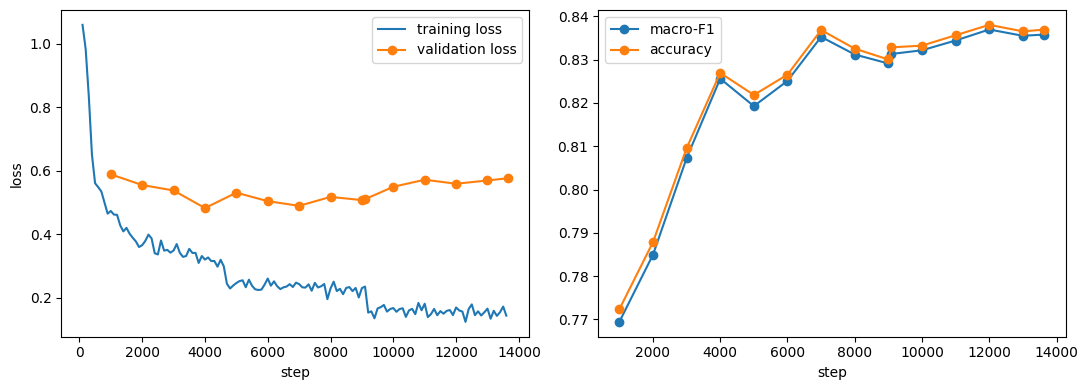

Mounted at /content/drive
['training_log.csv', 'training_config.json', 'training_curves.png']


In [ ]:
import os, glob, json, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/fever_project'
R = f'{ROOT}/results'

# 1) the log saved inside the newest available checkpoint
cks = sorted(glob.glob(f'{ROOT}/checkpoints/run1/checkpoint-*'), key=lambda p: int(p.rsplit('-', 1)[1]))
latest = cks[-1]
state = json.load(open(f'{latest}/trainer_state.json'))
log = pd.DataFrame(state['log_history']); log['source'] = f'trainer_state.json ({os.path.basename(latest)})'
print('log taken from:', latest, '| global_step there:', state['global_step'],
      '| best checkpoint:', state.get('best_model_checkpoint'), '| best macro_f1:', state.get('best_metric'))

# 2) the last two evaluation rows, transcribed from the Cell 17 table pasted in the chat
extra = pd.DataFrame([
    dict(step=9000, epoch=1.98, eval_loss=0.512037, eval_accuracy=0.832750, eval_macro_precision=0.834040, eval_macro_recall=0.832732, eval_macro_f1=0.831154),
    dict(step=9092, epoch=2.0,  eval_loss=0.510289, eval_accuracy=0.832850, eval_macro_precision=0.834045, eval_macro_recall=0.832833, eval_macro_f1=0.831324),
]); extra['source'] = 'transcribed from Cell 17 output'
extra = extra[~extra['step'].isin(log.dropna(subset=['eval_loss'])['step'])]       # only add rows we do not already have
log = pd.concat([log, extra], ignore_index=True)
log.to_csv(f'{R}/training_log.csv', index=False)

# 3) training_config.json from the planned config and segment record on Drive
planned = json.load(open(f'{R}/run1_config_planned.json'))
segs = json.load(open(f'{R}/run1_segments.json'))
config = dict(planned,
    gpu=segs[-1].get('gpu'), segments=len(segs), segment_status=[s['status'] for s in segs],
    training_minutes_recorded=round(sum(s['seconds'] or 0 for s in segs if s['status'] == 'finished') / 60, 1),
    best_checkpoint=f'{ROOT}/checkpoints/run1/checkpoint-7000', best_val_macro_f1_during_training=0.8347263807543035,
    final_global_step=9092,
    versions=dict(torch='2.14.1+cu130', transformers='5.22.1'),
    note='best_val_macro_f1, final_global_step and versions were transcribed from the Cell 17/18 output in the training session; the rest was read from files.',
    data_notes='fill in: wiki coverage, dropped claims, NEI method, NEI audit result')
json.dump(config, open(f'{R}/training_config.json', 'w'), indent=2)
print(json.dumps(config, indent=2))

# 4) learning curves
tr = log.dropna(subset=['loss']); ev = log.dropna(subset=['eval_loss']).sort_values('step')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(tr['step'], tr['loss'], label='training loss'); ax[0].plot(ev['step'], ev['eval_loss'], marker='o', label='validation loss')
ax[0].set_xlabel('step'); ax[0].set_ylabel('loss'); ax[0].legend()
ax[1].plot(ev['step'], ev['eval_macro_f1'], marker='o', label='macro-F1'); ax[1].plot(ev['step'], ev['eval_accuracy'], marker='o', label='accuracy')
ax[1].set_xlabel('step'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{R}/training_curves.png', dpi=150); plt.show()

# 5) make sure Drive finishes writing, then confirm from a fresh listing
drive.flush_and_unmount(); drive.mount('/content/drive')
print([f for f in ['training_log.csv', 'training_config.json', 'training_curves.png'] if os.path.exists(f'{R}/{f}')])